In [58]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# repo root, so src/ imports work
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import load_merged_table, parse_dates, temporal_split

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

# extracted folder if present, otherwise the archive
DATA = ROOT / "data" / "raw" / "full"
if not DATA.exists():
    DATA = ROOT / "data" / "raw" / "kenya_ppra_full.csv.tar.gz"

df = parse_dates(load_merged_table(DATA))
aw, train = temporal_split(df)
X_train, X_test = aw[train], aw[~train]

print("data:", DATA)
print("merged table (N x P):", df.shape)
print("scoring unit (awarded, in window):", aw.shape, "| excluded:", int(df["value_amount"].notna().sum()) - len(aw))
print(f"train: {len(X_train):,} ({train.mean():.1%}) | test: {len(X_test):,} ({1 - train.mean():.1%})")

data: /Users/razanosman/kenya-procurement-triage/data/raw/full
merged table (N x P): (277325, 23)
scoring unit (awarded, in window): (108984, 23) | excluded: 179
train: 72,585 (66.6%) | test: 36,399 (33.4%)


## Missingness

status                            99.88
tender_awardCriteria              73.39
contractPeriod_startDate          50.90
supplier_name                     33.76
contractPeriod_endDate            11.15
dateSigned                         6.35
tender_mainProcurementCategory     0.11
tender_tenderPeriod_startDate      0.04 



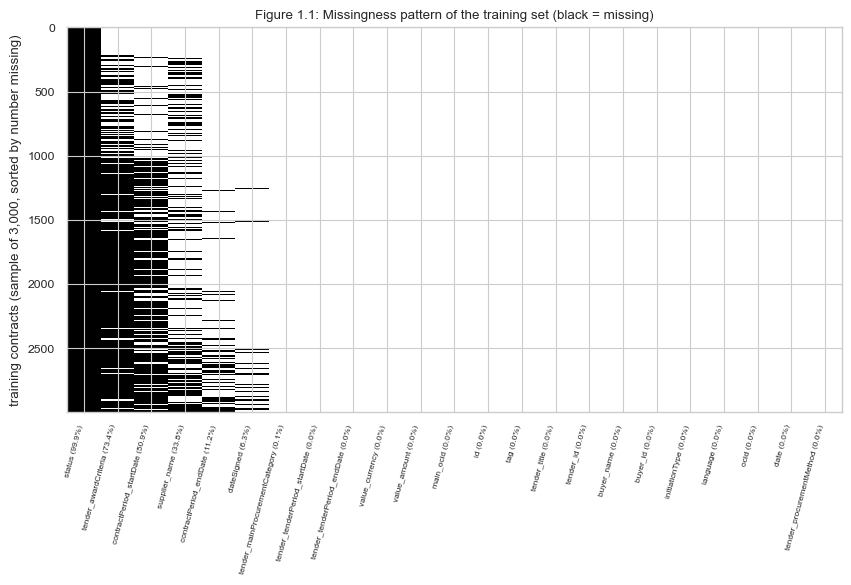

Little's MCAR test: chi2 = 2,526.8, df = 16, p = 0.00e+00, missingness patterns = 8



,missing %,chi2,dof,p,Cramer V,missing % by group,MCAR
column,,,,,,,
dateSigned,6.35,279.0,2,2.575732e-61,0.062,"{'open': 6.1, 'restricted': 13.78, 'non-competitive': 4.88}",rejected
contractPeriod_startDate,50.90,148.9,2,4.746722e-33,0.045,"{'open': 51.42, 'restricted': 39.71, 'non-competitive': 50.0}",rejected
contractPeriod_endDate,11.15,84.2,2,5.159527e-19,0.034,"{'open': 11.0, 'restricted': 9.47, 'non-competitive': 16.04}",rejected
supplier_name,33.76,42.2,2,6.762244e-10,0.024,"{'open': 33.47, 'restricted': 39.21, 'non-competitive': 35.09}",rejected
tender_mainProcurementCategory,0.06,44.3,2,2.433052e-10,0.027,"{'open': 0.05, 'restricted': 0.37, 'non-competitive': 0.0}",rejected
tender_awardCriteria,74.27,332.5,2,6.324472e-73,0.074,"{'open': 75.23, 'restricted': 67.0, 'non-competitive': 61.55}",rejected


In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.constants import METHOD_LEVEL, LEVEL_NAMES
from src.diagnostics import little_mcar, missingness_tests

sns.set_theme(style="whitegrid", context="paper")


def save(fig, name):
    fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
    plt.show()


# missing % per column, training set
miss_train = (X_train.isna().mean() * 100).round(2).sort_values(ascending=False)
print(miss_train[miss_train > 0].to_string(), "\n")

# Figure 1.1
order = miss_train.index
sample = X_train.sample(min(3000, len(X_train)), random_state=0)
sample = sample.loc[sample[order].isna().sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(sample[order].isna().to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{c} ({miss_train[c]:.1f}%)" for c in order], rotation=75, ha="right", fontsize=6)
ax.set_ylabel("training contracts (sample of 3,000, sorted by number missing)")
ax.set_title("Figure 1.1: Missingness pattern of the training set (black = missing)")
save(fig, "fig1_1_missingness_heatmap.png")

# Little's MCAR test on the numeric block (days measured from the bidding deadline)
end = X_train["tender_tenderPeriod_endDate"]
block = pd.DataFrame({
    "log_value": np.log1p(X_train["value_amount"]),
    "days_to_signing": (X_train["dateSigned"] - end).dt.days,
    "contract_start_offset": (X_train["contractPeriod_startDate"] - end).dt.days,
    "contract_end_offset": (X_train["contractPeriod_endDate"] - end).dt.days,
})
chi2, dof, p, n_pat = little_mcar(block)
print(f"Little's MCAR test: chi2 = {chi2:,.1f}, df = {dof}, p = {p:.2e}, missingness patterns = {n_pat}\n")

# chi-square and Cramer's V against competition level
level = X_train["tender_procurementMethod"].map(METHOD_LEVEL)
award_cols = ["dateSigned", "contractPeriod_startDate", "contractPeriod_endDate", "supplier_name"]
tests_aw = missingness_tests(X_train, award_cols, level, LEVEL_NAMES)
tenders = X_train.drop_duplicates("ocid")
tests_t = missingness_tests(tenders, ["tender_mainProcurementCategory", "tender_awardCriteria"],
                            tenders["tender_procurementMethod"].map(METHOD_LEVEL), LEVEL_NAMES)
pd.concat([tests_aw, tests_t])

In [81]:
pd.set_option("display.max_colwidth", None)

# missing % by year across the whole scoring unit
year = aw["tender_tenderPeriod_endDate"].dt.year
cols = ["dateSigned", "contractPeriod_startDate", "contractPeriod_endDate", "supplier_name"]
print((aw[cols].isna().groupby(year).mean() * 100).round(1), "\n")

# same chi-square test, but against year instead of procurement method
missingness_tests(aw, cols, year)

                             dateSigned  contractPeriod_startDate  \
tender_tenderPeriod_endDate                                         
2018                               17.2                      21.5   
2019                                5.6                      12.5   
2020                                4.2                      23.7   
2021                                1.7                      82.8   
2022                                0.1                      87.1   
2023                               10.4                      38.7   
2024                               39.5                       2.2   
2025                                0.8                       2.0   
2026                                0.6                       1.4   

                             contractPeriod_endDate  supplier_name  
tender_tenderPeriod_endDate                                         
2018                                           24.2           13.2  
2019                             

,missing %,chi2,dof,p,Cramer V,missing % by group,MCAR
column,,,,,,,
dateSigned,13.66,21076.4,8,0.000000e+00,0.440,"{2018: 17.2, 2019: 5.56, 2020: 4.17, 2021: 1.72, 2022: 0.12, 2023: 10.44, 2024: 39.52, 2025: 0.77, 2026: 0.59}",rejected
contractPeriod_startDate,34.59,49490.0,8,0.000000e+00,0.674,"{2018: 21.52, 2019: 12.51, 2020: 23.73, 2021: 82.78, 2022: 87.07, 2023: 38.75, 2024: 2.16, 2025: 1.96, 2026: 1.41}",rejected
contractPeriod_endDate,10.45,1100.8,8,2.556862e-232,0.101,"{2018: 24.17, 2019: 8.83, 2020: 8.19, 2021: 11.6, 2022: 10.4, 2023: 10.55, 2024: 9.19, 2025: 9.1, 2026: 7.38}",rejected
supplier_name,26.83,15947.9,8,0.000000e+00,0.383,"{2018: 13.17, 2019: 63.47, 2020: 68.93, 2021: 36.76, 2022: 25.3, 2023: 26.88, 2024: 18.12, 2025: 0.47, 2026: 0.78}",rejected


In [82]:
tend = aw.drop_duplicates("ocid")
t_year = tend["tender_tenderPeriod_endDate"].dt.year
print((tend["tender_awardCriteria"].isna().groupby(t_year).mean() * 100).round(1), "\n")
missingness_tests(tend, ["tender_awardCriteria"], t_year)

tender_tenderPeriod_endDate
2018      0.3
2019      1.7
2020      8.7
2021     78.9
2022     99.5
2023     98.8
2024     98.5
2025    100.0
2026    100.0
Name: tender_awardCriteria, dtype: float64 



,missing %,chi2,dof,p,Cramer V,missing % by group,MCAR
column,,,,,,,
tender_awardCriteria,82.5,74587.2,8,0.0,0.903,"{2018: 0.31, 2019: 1.72, 2020: 8.7, 2021: 78.92, 2022: 99.54, 2023: 98.81, 2024: 98.48, 2025: 99.99, 2026: 99.96}",rejected


In [83]:
# earlier contracts per buyer at the moment of each contract (aw is sorted by date)
earlier = aw.groupby("buyer_id").cumcount()

counts = X_train.groupby("buyer_id").size()
print("buyers in training:", len(counts))
print("buyers with 100+ training contracts:", int((counts >= 100).sum()))
print(f"training contracts with 100+ earlier contracts from their buyer: {(earlier[train] >= 100).mean():.1%}")
print(f"test contracts with 100+ earlier contracts from their buyer: {(earlier[~train] >= 100).mean():.1%}")

buyers in training: 494
buyers with 100+ training contracts: 178
training contracts with 100+ earlier contracts from their buyer: 63.8%
test contracts with 100+ earlier contracts from their buyer: 85.7%


buyer groups (training): {'agency': 255, 'education': 117, 'county': 97, 'ministry': 25} 

indicator coverage (% of contracts)
                           train   test
f1_direct_award            100.0  100.0
f3_decision_period          93.7   71.8
f4_supplier_concentration   65.1   86.4
f5_benford_deviation        92.9   97.7
f5 under strict 100 rule    62.6   85.3 

signed before bidding closed: train 5.4%, test 9.0%
R(c) train: mean 0.278, median 0.277, skew 0.40
R(c) test:  mean 0.252, median 0.257


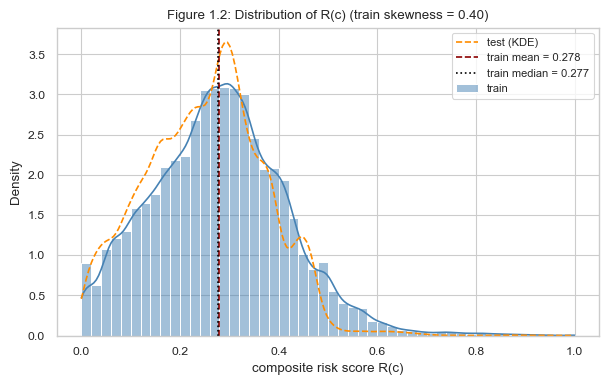

In [84]:
from scipy import stats
from src.features import IndicatorBuilder, INDICATORS, buyer_group

# fit on training contracts only, then score both sets
builder = IndicatorBuilder(k_prior=100, min_prior=10).fit(X_train)
F_train = builder.transform(X_train)
F_test = builder.transform(X_test)

print("buyer groups (training):", buyer_group(X_train.drop_duplicates("buyer_id")["buyer_name"]).value_counts().to_dict(), "\n")

# indicator coverage, with the Benford fallback shown against the strict 100 rule
cov = pd.DataFrame({
    "train": F_train[INDICATORS].notna().mean() * 100,
    "test": F_test[INDICATORS].notna().mean() * 100,
}).round(1)
cov.loc["f5 under strict 100 rule"] = [(F_train["n_prior_awards"] >= 100).mean() * 100,
                                       (F_test["n_prior_awards"] >= 100).mean() * 100]
print("indicator coverage (% of contracts)")
print(cov.round(1).to_string(), "\n")

print(f"signed before bidding closed: train {F_train['is_signed_pre_closure'].mean():.1%}, "
      f"test {F_test['is_signed_pre_closure'].mean():.1%}")
print(f"R(c) train: mean {F_train['R'].mean():.3f}, median {F_train['R'].median():.3f}, "
      f"skew {stats.skew(F_train['R'].dropna()):.2f}")
print(f"R(c) test:  mean {F_test['R'].mean():.3f}, median {F_test['R'].median():.3f}")

# Figure 1.2: target distribution
r = F_train["R"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(r, bins=50, kde=True, kde_kws={"clip": (0, 1)}, stat="density", ax=ax, color="steelblue", label="train")
sns.kdeplot(F_test["R"].dropna(), clip=(0, 1), ax=ax, color="darkorange", ls="--", label="test (KDE)")
ax.axvline(r.mean(), color="darkred", ls="--", label=f"train mean = {r.mean():.3f}")
ax.axvline(r.median(), color="black", ls=":", label=f"train median = {r.median():.3f}")
ax.set_xlabel("composite risk score R(c)")
ax.set_title(f"Figure 1.2: Distribution of R(c) (train skewness = {stats.skew(r):.2f})")
ax.legend(fontsize=8)
save(fig, "fig1_2_target_distribution.png")

In [85]:
from src.data import read_tables
from src.features import normalise_names

parties, sup = read_tables(DATA, ["parties", "awards_suppliers"])
ps = parties[parties["roles"].astype(str).str.contains("supplier")].copy()
ps["norm"] = normalise_names(ps["name"])
print(f"supplier party rows: {len(ps):,} | with identifier_id: {ps['identifier_id'].notna().mean():.1%}")
print("identifier schemes:", ps["identifier_scheme"].value_counts(dropna=False).head().to_dict(), "\n")

# is identifier_id one number per company?
known = ps.dropna(subset=["identifier_id"])
ids_per_name = known.groupby("norm")["identifier_id"].nunique()
names_per_id = known.groupby("identifier_id")["norm"].nunique()
print(f"names with a single identifier: {(ids_per_name == 1).mean():.1%} (of {len(ids_per_name):,} names)")
print(f"identifiers with a single name: {(names_per_id == 1).mean():.1%} (of {len(names_per_id):,} identifiers)\n")

print("examples of one identifier under several names:")
for i in names_per_id[names_per_id > 1].sort_values(ascending=False).index[:8]:
    print(" ", int(i), list(known.loc[known["identifier_id"] == i, "norm"].unique()[:4]))

# can the winning suppliers be linked to a party identifier? (same process, same name)
sup["norm"] = normalise_names(sup["name"])
lookup = ps[["main_ocid", "norm", "identifier_id"]].drop_duplicates(["main_ocid", "norm"])
linked = sup.merge(lookup, on=["main_ocid", "norm"], how="left")
print(f"\nwinning suppliers linked to an identifier: {linked['identifier_id'].notna().mean():.1%}")

supplier party rows: 552,087 | with identifier_id: 100.0%
identifier schemes: {'Bidders': 552087} 

names with a single identifier: 63.6% (of 174,028 names)
identifiers with a single name: 100.0% (of 552,087 identifiers)

examples of one identifier under several names:

winning suppliers linked to an identifier: 88.2%


In [86]:
import time
from src.entity_resolution import candidate_pairs, acronym_pairs, labelling_sample

# training supplier names only (the matcher is fit on train)
train_names = normalise_names(X_train["supplier_name"]).dropna()
volume = train_names.value_counts()
print(f"training awards with a supplier: {len(train_names):,} | distinct cleaned names: {len(volume):,}")
print(f"high-volume cut-off (top 5% of names): {volume.quantile(0.95):.0f}+ awards\n")

t0 = time.time()
fuzzy = candidate_pairs(volume.index, min_score=80)
acr = acronym_pairs(volume.index)
print(f"candidate pairs: {len(fuzzy):,} fuzzy (score 80+), {len(acr):,} acronym | {time.time() - t0:.0f}s")
print(f"same words in a different order (score 100, merged without labelling): {(fuzzy['score'] == 100).sum():,}\n")

sample, sizes = labelling_sample(pd.concat([fuzzy, acr], ignore_index=True), volume)
print("pairs in each stratum (population) and in the sample")
print(pd.DataFrame({"population": sizes, "sample": sample["stratum"].value_counts()}).to_string(), "\n")

labels_dir = ROOT / "data" / "labels"
labels_dir.mkdir(parents=True, exist_ok=True)
sample.to_csv(labels_dir / "entity_pairs_to_label.csv", index=False)
sizes.to_csv(labels_dir / "entity_pair_strata.csv")
print("saved", len(sample), "pairs to", labels_dir / "entity_pairs_to_label.csv")
sample.head(10)

training awards with a supplier: 48,079 | distinct cleaned names: 21,963
high-volume cut-off (top 5% of names): 6+ awards

candidate pairs: 199,827 fuzzy (score 80+), 29 acronym | 4s
same words in a different order (score 100, merged without labelling): 14

pairs in each stratum (population) and in the sample
                population  sample
stratum                           
80-85 | high         15574      22
80-85 | small       151024      22
85-90 | high          2880      22
85-90 | small        25121      22
90-95 | high           667      22
90-95 | small         3127      22
95-100 | high          337      22
95-100 | small        1083      22
acronym                 29      24 

saved 200 pairs to /Users/razanosman/kenya-procurement-triage/data/labels/entity_pairs_to_label.csv


,pair_id,stratum,score,name_a,name_b,awards_a,awards_b,label
0,1,80-85 | high,81,INOVATE ENTERPRISES LTD,FINETOPS ENTERPRISES LTD,7,1,
1,2,95-100 | small,95,MORKI VENTURES LTD,MORIKIN VENTURES LTD,2,1,
2,3,90-95 | high,90,STIMAL OFFICE SUPPLIES LTD,SAI OFFICE SUPPLIES LTD,6,2,
3,4,90-95 | high,93,MADISON GENERAL INSURANCE,MADISON GENERAL INSURANCE LTD,16,3,
4,5,acronym,24,MHE LTD,METUMI HEIGHTS ENTERPRISES,1,2,
5,6,acronym,19,KOI,K ONEGE INVESTMENT,1,2,
6,7,80-85 | high,82,PHARMACO HEALTHCARE LTD,PRODGY HEALTHCARE LTD,10,1,
7,8,95-100 | high,97,DELLAN HEIGHTS ENTERPRISES LTD,DELAN HEIGHTS ENTERPRISE LTD,18,1,
8,9,80-85 | high,82,RICANA ENTERPRISES LTD,SAWAGA ENTERPRISES LTD,26,1,
9,10,95-100 | high,98,OPTIMAL ENTREPRENEUR,OPTIMAL ENTREPRENEURS,9,1,


In [ ]:
from src.entity_resolution import evaluate

labels_dir = ROOT / "data" / "labels"
labelled = pd.read_csv(labels_dir / "entity_pairs_labelled.csv", dtype={"label": str})
sizes = pd.read_csv(labels_dir / "entity_pair_strata.csv", index_col=0).iloc[:, 0]
print("labels:", labelled["label"].fillna("blank").value_counts().to_dict(), "\n")

# acronym rule on its own
acr = labelled[labelled["stratum"] == "acronym"]
dec = acr["label"].isin(["0", "1"])
print(f"acronym pairs: {len(acr)} | decided {dec.sum()} | same business {(acr['label'] == '1').sum()}"
      f" -> precision {(acr['label'] == '1').sum() / dec.sum():.2f}\n")

for name, use_acr in [("with acronym rule", True), ("without acronym rule", False)]:
    _, full, n = evaluate(labelled, sizes, use_acronym=use_acr)
    print(f"all suppliers, {name} ({n} labelled pairs, 95% bootstrap interval)")
    print(full.to_string(index=False), "\n")

# split by supplier volume: high-volume vs small suppliers
for v in ["high", "small"]:
    _, full, n = evaluate(labelled[labelled["stratum"].str.endswith(v)], sizes, use_acronym=False)
    print(f"{v}-volume suppliers ({n} labelled pairs)")
    print(full.to_string(index=False), "\n")

labels: {'0': 115, '1': 69, 'blank': 16} 

acronym pairs: 24 | decided 17 | same business 6 -> precision 0.35

all suppliers, with acronym rule (184 labelled pairs, 95% bootstrap interval)
 threshold           metric  estimate   low  high
        85        precision     0.101 0.077 0.126
        85           recall     1.000 1.000 1.000
        85 false-match rate     0.152 0.149 0.155
        90        precision     0.540 0.418 0.667
        90           recall     0.844 0.720 0.959
        90 false-match rate     0.012 0.009 0.015
        95        precision     0.912 0.800 0.988
        95           recall     0.394 0.311 0.513
        95 false-match rate     0.001 0.000 0.001 

all suppliers, without acronym rule (184 labelled pairs, 95% bootstrap interval)
 threshold           metric  estimate   low  high
        85        precision     0.101 0.077 0.125
        85           recall     0.997 0.995 0.999
        85 false-match rate     0.152 0.148 0.155
        90        precision 

### Entity resolution option A: pre-specified test (written before fresh labelling)

- Option A = merge if cores are identical (after removing LTD, CO, AND, THE, M/S, T/A and plural S), or core score ≥ 95.
- Option B = merge if original token sort ratio ≥ 95 (selected on the first 184 labels).
- Both are evaluated only on a fresh sample that excludes the first 200 pairs.
- Adopt A if its precision is ≥ 0.90 and its recall is higher than B's on the same fresh pairs. Otherwise keep B.
- Core thresholds 90 and "identical cores only" are reported as sensitivity checks, not used to choose.

In [88]:
import importlib, src.entity_resolution
importlib.reload(src.entity_resolution)
from src.entity_resolution import core_pairs, fresh_sample

t0 = time.time()
cpairs = core_pairs(volume.index, min_score=85)
print(f"option A candidate pairs: {len(cpairs):,} | {time.time() - t0:.0f}s")
print(f"names merged by identical cores alone: {(cpairs['core_score'] == 100).sum():,} pairs\n")

old = pd.read_csv(labels_dir / "entity_pairs_labelled.csv")
fresh, fresh_sizes = fresh_sample(cpairs, volume, exclude=old, per_stratum=15)
print(pd.DataFrame({"population": fresh_sizes, "sample": fresh["stratum"].value_counts()}).to_string(), "\n")

fresh.to_csv(labels_dir / "entity_pairs_fresh_to_label.csv", index=False)
fresh_sizes.to_csv(labels_dir / "entity_pair_fresh_strata.csv")
print("saved", len(fresh), "pairs")
fresh.head(10)

option A candidate pairs: 26,057 | 3s
names merged by identical cores alone: 2,671 pairs

            population  sample
stratum                       
85-90            19256      15
90-95             2979      15
95-100            1084      15
exact core        2634      15 

saved 60 pairs


,pair_id,stratum,core_score,orig_score,name_a,name_b,awards_a,awards_b,label
0,1,95-100,95,80,AUTOEXPRESS,AUTOXPRESS LTD,3,26,
1,2,95-100,96,98,VILLA SURGICAL AND EQUIPMENTS,VILLA SURGICAL S AND EQUIPMENT,2,1,
2,3,85-90,88,80,VINNIM ENTERPRISES,VIONNE ENTERPRISES LTD,1,2,
3,4,exact core,100,80,BRITAM INSURANCE,BRITAM INSURANCES CO LTD,9,1,
4,5,exact core,100,90,NAIROBI IRONMONGERS,NAIROBI IRONMONGERS LTD,2,8,
5,6,95-100,95,87,BEMWATECH ENTERPRISES,BREWATECH ENTERPRISES LTD,1,1,
6,7,95-100,98,98,MOTORSZILLA ENTEPRISES,MOTORSZILLA ENTERPRISES,1,8,
7,8,95-100,97,88,ZAKALE EXPEDITIONS LTD,ZAKALE EXPENDITIONS,23,12,
8,9,95-100,98,99,TRIPLE A AGENCIES GENERAL SUPPLIERS,TRIPLE A AGENCIES GENERAL SUPPLIES,1,1,
9,10,90-95,91,82,KEVCY ENTERPRISES,KEVICK ENTERPRISES LTD,2,2,


In [89]:
# pairs option B would merge (original score 95+) that option A never lists as candidates
in_a = set(zip(cpairs["name_a"], cpairs["name_b"]))
b_pairs = fuzzy[fuzzy["score"] >= 95]
missed = b_pairs[[(min(a, b), max(a, b)) not in in_a
                  for a, b in zip(b_pairs["name_a"], b_pairs["name_b"])]]
print(f"option B merges: {len(b_pairs):,} | outside option A's candidates: {len(missed):,}")
missed.head(20)

option B merges: 1,434 | outside option A's candidates: 2


,name_a,name_b,score,kind
31282,ISAACWELLS LTD,ISAACWELLS LT5D,97,fuzzy
152240,CASCADE CO LD,CASCADE CO LTD,96,fuzzy


### Supplier resolver: cluster check (written before running on real data)

- The labelled samples validated pairs, not clusters. Linking pairs transitively (chaining) can join names that never matched directly.
- Inspect by hand: the 8 largest clusters, and every chained cluster whose lowest direct core score is below 90.
- If any contains different firms, the clustering step has a correctness problem and is fixed before f4 is used. Option A's pair rule (identical cores or core score ≥ 95) is not retuned.

In [90]:
import importlib, src.entity_resolution, src.features
importlib.reload(src.entity_resolution); importlib.reload(src.features)
from src.features import IndicatorBuilder, normalise_names

t0 = time.time()
ib_res = IndicatorBuilder().fit(X_train)                          # option A resolver, training names only
ib_raw = IndicatorBuilder(resolve_suppliers=False).fit(X_train)   # stage-1 names, as before
res = ib_res.resolver_
print(f"fitted both builders in {time.time() - t0:.0f}s\n")

# 1. what the resolver did on training names
cl = res.clusters_
per_id = cl.groupby("id").agg(names=("name", "size"), awards=("awards", "sum"))
print(f"training supplier names: {len(cl):,} -> identities: {res.n_clusters_:,} "
      f"({len(cl) - res.n_clusters_:,} names merged into another)")
print("names per identity:", per_id["names"].value_counts().sort_index().to_dict(), "\n")

# 2. largest clusters, to check for chaining
print("largest clusters:")
for i in per_id.sort_values("names", ascending=False).head(8).index:
    members = cl.loc[cl["id"] == i, "name"].tolist()
    print(f"  [{len(members)}] {i}: {members[:12]}{' ...' if len(members) > 12 else ''}")

# chained clusters: some members only linked through others (lowest direct core score < 95)
from rapidfuzz import process, fuzz
from src.entity_resolution import core_name
low = {}
for i, g in cl[cl["cluster_size"] > 2].groupby("id"):
    cores = [" ".join(sorted(core_name(n).split())) for n in g["name"]]
    low[i] = process.cdist(cores, cores, scorer=fuzz.ratio).min()
low = pd.Series(low, dtype=float)
print(f"\nclusters with 3+ names: {len(low):,} | chained: {(low < 95).sum():,} | "
      f"chained with a direct score below 90: {(low < 90).sum():,}")
for i in low[low < 90].sort_values().head(5).index:
    print(f"  min direct score {low[i]:.0f}: {cl.loc[cl['id'] == i, 'name'].tolist()[:8]}")

# 3. how test-period names were resolved (training identities stay fixed)
tn = pd.Series(pd.unique(normalise_names(X_test["supplier_name"]).dropna()))
tid = res.transform(tn)
seen = tn.isin(set(res.name_map_))
new = tid.astype(str).str.startswith("~new:")
print(f"\ntest-period supplier names: {len(tn):,} | seen in training {seen.sum():,} | "
      f"linked to a training identity {(~seen & ~new).sum():,} | new identities {new.sum():,}\n")

# 4. effect on f4
for name, X in [("train", X_train), ("test", X_test)]:
    a = ib_res.transform(X)["f4_supplier_concentration"]
    b = ib_raw.transform(X)["f4_supplier_concentration"]
    both = a.notna() & b.notna()
    d = (a - b)[both]
    print(f"{name}: f4 coverage {a.notna().mean():.1%} (was {b.notna().mean():.1%}) | "
          f"changed by > 0.01: {(d.abs() > 0.01).mean():.1%} | mean change {d.mean():+.4f} | "
          f"Spearman with old f4 {a[both].corr(b[both], method='spearman'):.3f}")

fitted both builders in 4s

training supplier names: 21,963 -> identities: 19,247 (2,716 names merged into another)
names per identity: {1: 17179, 2: 1653, 3: 275, 4: 88, 5: 32, 6: 10, 7: 6, 8: 2, 10: 1, 13: 1} 

largest clusters:
  [13] VILLA SURGICAL EQUIPMENT LTD: ['VILLA SURGICAL EQUIPMENT LTD', 'VILLA SURGICAL EQUIPMENTS LTD', 'VILLA SURGICAL AND EQUIPMENTS LTD', 'VILLA SURGICAL AND EQUIPMENT LTD', 'VILLA SURGICALS EQUIPMENTS LTD', 'M S VILLA SURGICAL AND EQUIPMENT LTD', 'VILLA SURGICAL AND EQUIPMENTS', 'VILLA SURGIAL AND EQUIPMENT LTD', 'VILLA SURGICAL AND EQUIPMENT', 'VILLA SURGICAL EQUIPMENT S LTD', 'VILLA SURGICAL S AND EQUIPMENT', 'VILLA SURGICALS EQUIPMENT'] ...
  [10] LONGROCK TOURS TRAVEL LTD: ['LONGROCK TOURS TRAVEL LTD', 'LONGROCK TOURS AND TRAVEL LTD', 'LONGROCK TOURS AND TRAVEL', 'LONGROCK TOURS TRAVEL', 'LONGROCK TOURS TRAVELS LTD', 'LONGROCK TOUR AND TRAVEL', 'LONGROCK TOURS AND TRAVELS', 'LONGROCK TOURS AND TRAVELS LTD', 'LONGROCK TOUR TRAVEL LTD', 'M S LONGROCK TOU

In [91]:
print(cl.loc[cl["id"] == "VILLA SURGICAL EQUIPMENT LTD", "name"].tolist())

['VILLA SURGICAL EQUIPMENT LTD', 'VILLA SURGICAL EQUIPMENTS LTD', 'VILLA SURGICAL AND EQUIPMENTS LTD', 'VILLA SURGICAL AND EQUIPMENT LTD', 'VILLA SURGICALS EQUIPMENTS LTD', 'M S VILLA SURGICAL AND EQUIPMENT LTD', 'VILLA SURGICAL AND EQUIPMENTS', 'VILLA SURGIAL AND EQUIPMENT LTD', 'VILLA SURGICAL AND EQUIPMENT', 'VILLA SURGICAL EQUIPMENT S LTD', 'VILLA SURGICAL S AND EQUIPMENT', 'VILLA SURGICALS EQUIPMENT', 'VILLA SURGICALS EQUIPMENTS']


In [92]:
# f6 step 1: explore before defining (training period only)
print("party roles (top 10):")
print(parties["roles"].astype(str).value_counts().head(10).to_string(), "\n")

key = "main_ocid" if "main_ocid" in X_train.columns else "ocid"
procs = pd.Index(X_train[key].dropna().unique())
p = ps[ps["main_ocid"].isin(procs)]
w = sup[sup["main_ocid"].isin(procs)]

n_names = p.groupby("main_ocid")["norm"].nunique()   # distinct supplier parties
n_rows = p.groupby("main_ocid").size()                # party rows
n_win = w.groupby("main_ocid")["norm"].nunique()      # distinct award winners
print(f"training processes: {len(procs):,} | with any supplier party: {n_names.size / len(procs):.1%}")
print("distinct supplier parties per process:",
      n_names.clip(upper=5).value_counts().sort_index().rename({5: "5+"}).to_dict())
print(f"processes where rows > distinct names (duplicates): {(n_rows > n_names).mean():.1%}")
both = n_win.index.intersection(n_names.index)
print(f"processes with fewer parties than winners (should be ~0): {(n_names[both] < n_win[both]).mean():.1%}\n")

# share of single-party processes by procurement method, at contract level
c = X_train[[key, "tender_procurementMethod"]].copy()
c["n_parties"] = c[key].map(n_names)
c["single"] = (c["n_parties"] == 1).astype(float).where(c["n_parties"].notna())
print("contracts by method: coverage and share with exactly one supplier party")
print(c.groupby("tender_procurementMethod").agg(
    contracts=("single", "size"), coverage=("n_parties", lambda s: s.notna().mean()),
    single_share=("single", "mean")).round(3).sort_values("contracts", ascending=False).to_string())

party roles (top 10):
roles
supplier    552087
buyer       260991 

training processes: 60,869 | with any supplier party: 84.6%
distinct supplier parties per process: {0: 11, 1: 12559, 2: 2451, 3: 17186, 4: 7280, '5+': 12007}
processes where rows > distinct names (duplicates): 1.6%
processes with fewer parties than winners (should be ~0): 0.1%

contracts by method: coverage and share with exactly one supplier party
                          contracts  coverage  single_share
tender_procurementMethod                                   
open                          66685     0.853         0.175
direct                         3088     0.731         0.944
selective                      2800     0.831         0.428
AlternativeSelection              6     1.000         0.500
SpeciallyPermitted                4     1.000         0.250
communityparticipartion           2     1.000         1.000


### f6 single bidding: pre-specified validation (written before the manual check)

- Definition: competitive procedures only (direct and specially permitted = not applicable). f6 = 1 if exactly one distinct supplier party (counted by cleaned core), 0 if two or more, missing if none.
- Check: 50 training-period competitive processes (20 with one party, 10 each with 2, 3 and 4+). For each, record the number of bids received from the PPRA portal or the award notice.
- Adopt f6 into R(c) if the data and the portal agree on single vs multiple bidding in at least 90% of the checked processes (45 of 50).
- 80 to 90%: keep f6 as a display flag only, not in R(c). Below 80%, or bid counts not available on the portal: f6 stays out of R(c) and is reported as pending validation.
- Secondary: exact agreement on the number of bids, and whether parties look like invited firms or submitted bids.

In [93]:
from src.entity_resolution import core_name

# distinct bidders per process, counted by cleaned core (LTD, M/S, plurals ignored)
p = ps[ps["main_ocid"].isin(procs) & ps["norm"].notna()].copy()
p["core"] = p["norm"].map(core_name)
n_core = p.groupby("main_ocid")["core"].nunique()
print(f"single by distinct names: {(n_names == 1).sum():,} | by distinct cores: {(n_core == 1).sum():,} processes\n")

# 50 competitive training processes for the manual check
comp = X_train[~X_train["tender_procurementMethod"].isin(["direct", "SpeciallyPermitted"])]
pool = pd.DataFrame({"n_parties": comp.drop_duplicates(key).set_index(key).index.map(n_core)},
                    index=comp.drop_duplicates(key)[key]).dropna()
pool["band"] = pd.cut(pool["n_parties"], [0, 1, 2, 3, 1e9], labels=["1", "2", "3", "4+"]).astype(str)
quota = {"1": 20, "2": 10, "3": 10, "4+": 10}
pick = pd.concat([g.sample(min(quota[b], len(g)), random_state=7) for b, g in pool.groupby("band")])

info_cols = [c for c in ["tender_id", "tender_title", "title", "buyer_name", "tender_procurementMethod",
                         "tender_tenderPeriod_endDate", "value_amount", "supplier_name"] if c in X_train.columns]
info = X_train.drop_duplicates(key).set_index(key).loc[pick.index, info_cols]
names = p.groupby("main_ocid")["norm"].apply(lambda s: " | ".join(sorted(s.unique())))
check = info.assign(n_parties=pick["n_parties"].astype(int), parties=names.reindex(pick.index),
                    portal_bids="", portal_source="", note="")
check = check.sample(frac=1, random_state=7).rename_axis("main_ocid").reset_index()
check.to_csv(labels_dir / "f6_manual_check.csv", index=False)
print("manual-check sample by number of parties:", check["n_parties"].clip(upper=4).value_counts().sort_index().to_dict())
print("saved", len(check), "processes to", labels_dir / "f6_manual_check.csv")
check.head(3)

single by distinct names: 12,559 | by distinct cores: 12,575 processes

manual-check sample by number of parties: {1: 20, 2: 10, 3: 10, 4: 10}
saved 50 processes to /Users/razanosman/kenya-procurement-triage/data/labels/f6_manual_check.csv


,main_ocid,tender_id,tender_title,buyer_name,tender_procurementMethod,tender_tenderPeriod_endDate,value_amount,supplier_name,n_parties,parties,portal_bids,portal_source,note
0,ocds-5whusi-CDA142/2021-2022,20220908222037-90703-CDA142/2021-2022,supply of fuel,Coast Development Authority,open,2021-11-16 21:00:00+00:00,100000.0,NaN,1,HELLER,,,
1,ocds-5whusi-55199,20210511175957-61713-CA/PROC/RFP/04/2020-2021,RE-TENDER FOR REQUEST FOR PROPOSAL (RFP) FOR PROVISION OF CONSULTANCY SERVICES FOR RE- CERTIFICATION OF QUALITY MANAGEMENT SYSTEM BASED ON ISO 9001:2015,Communications Authority of Kenya,open,2021-06-01 21:00:00+00:00,2738760.0,MAIER CONSULTING,1,MAIER CONSULTING,,,
2,ocds-5whusi-068537,20211006161938-68537-NCC/PSM/T/178/2021-2022,SUPPLY AND DELIVERY OF OFFICE FURNITURE,Nairobi County Government,open,2021-10-13 21:00:00+00:00,6823780.0,NaN,2,GENETEX GENERAL AGENCIES | PRIME MAYDAY SOLUTIONS LTD,,,


In [94]:
# f6 single bidding: descriptive record and validation result (not in R(c): pending validation)
from scipy.stats import beta

def exact_ci(k, n):
    lo = beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
    return lo, hi

# contract-level f6 on training data
competitive = ~X_train["tender_procurementMethod"].isin(["direct", "SpeciallyPermitted"])
n_bid = X_train[key].map(n_core)
f6 = (n_bid == 1).astype(float).where(n_bid.notna() & competitive)
print(f"training contracts: {len(X_train):,} | competitive {competitive.mean():.1%} | "
      f"f6 defined {f6.notna().mean():.1%} | single-bidder share {f6.mean():.1%}")
print("single-bidder share by method:",
      f6.groupby(X_train["tender_procurementMethod"]).mean().dropna().round(3).to_dict(), "\n")

# manual check against PPIP
chk = pd.read_csv(labels_dir / "f6_manual_check_done.csv")
chk["portal_bids"] = pd.to_numeric(chk["portal_bids"], errors="coerce")
ver = chk[chk["portal_bids"].notna()]
pilot = chk["note"].fillna("").str.contains("pilot")
k_cov, n_cov = len(ver), len(chk)
same = ((ver["portal_bids"] == 1) == (ver["n_parties"] == 1))
exact = ver["portal_bids"] == ver["n_parties"]
rows = [("coverage (verified / sampled)", k_cov, n_cov),
        ("single vs multiple agreement", same.sum(), len(ver)),
        ("same, excluding pilot rows", same[~pilot[ver.index]].sum(), (~pilot[ver.index]).sum()),
        ("exact number of bids", exact.sum(), len(ver))]
for name, k, n in rows:
    lo, hi = exact_ci(k, n)
    print(f"{name}: {k}/{n} = {k / n:.0%} (95% CI {lo:.0%} to {hi:.0%})")

band = chk["n_parties"].clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
print("\nverified by number of parties:",
      pd.crosstab(band, chk["portal_bids"].notna()).rename(columns={False: "not verified", True: "verified"}).to_dict("index"))
print("\nall-agree lower bound by verified sample size:",
      {n: round(exact_ci(n, n)[0], 2) for n in [15, 30, 35]})
print(f"\npre-specified minimum: 30 verified | verified: {k_cov} -> f6 stays out of R(c), pending validation")

training contracts: 72,585 | competitive 95.7% | f6 defined 81.6% | single-bidder share 18.6%
single-bidder share by method: {'AlternativeSelection': 0.5, 'communityparticipartion': 1.0, 'open': 0.176, 'selective': 0.428} 

coverage (verified / sampled): 15/50 = 30% (95% CI 18% to 45%)
single vs multiple agreement: 15/15 = 100% (95% CI 78% to 100%)
same, excluding pilot rows: 13/13 = 100% (95% CI 75% to 100%)
exact number of bids: 15/15 = 100% (95% CI 78% to 100%)

verified by number of parties: {'1': {'not verified': 13, 'verified': 7}, '2': {'not verified': 4, 'verified': 6}, '3': {'not verified': 9, 'verified': 1}, '4+': {'not verified': 9, 'verified': 1}}

all-agree lower bound by verified sample size: {15: np.float64(0.78), 30: np.float64(0.88), 35: np.float64(0.9)}

pre-specified minimum: 30 verified | verified: 15 -> f6 stays out of R(c), pending validation


value (train, n=72,585): median 499,500 | Q1 110,106 | Q3 2,884,340 | max 160,583,268,000 | zeros 759
  IQR upper bound 7,045,691: 12.7% of train above (7.8% of test)
  P99 164,879,639: 1.0% of train above (0.5% of test)
  raw                skew  137.48 | kurtosis  20892.26
  log1p              skew   -1.35 | kurtosis      5.34
  winsorise + log1p  skew   -1.44 | kurtosis      5.39
  same, zeros out    skew   -0.72 | kurtosis      2.84

share above each bound, by procurement category:
          contracts  above_iqr  above_p99
cat                                      
goods         28908      0.055      0.004
missing          78      0.026      0.000
services      16837      0.115      0.010
works         26762      0.212      0.017 

days_to_signing (train, n=67,978): median 24 | min -3911 | max 1499 | negative 5.4%
  IQR bounds -69 to 131: 7.6% outside
  raw         skew   -8.33 | kurtosis    125.08
  signed log  skew   -1.86 | kurtosis      4.47


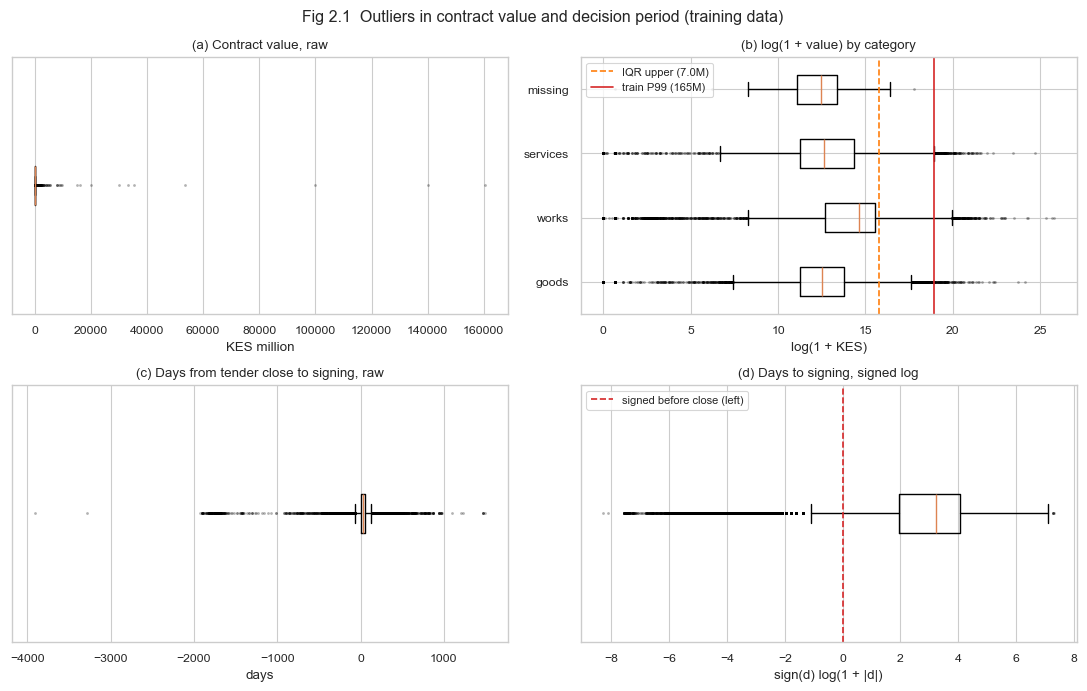

In [95]:
# step 4: outliers on training data (thresholds fitted on train, applied to test)
from scipy.stats import skew, kurtosis

def shape(x):
    x = pd.Series(x).dropna()
    return f"skew {skew(x):7.2f} | kurtosis {kurtosis(x):9.2f}"

signed_log = lambda d: np.sign(d) * np.log1p(np.abs(d))

# contract value
v = X_train["value_amount"].astype(float)
q1, q3 = v.quantile([0.25, 0.75])
iqr_hi = q3 + 1.5 * (q3 - q1)
p99 = v[v > 0].quantile(0.99)  # positive values only, zeros have their own flag
vt = X_test["value_amount"].astype(float)
print(f"value (train, n={v.notna().sum():,}): median {v.median():,.0f} | Q1 {q1:,.0f} | Q3 {q3:,.0f} | max {v.max():,.0f} | zeros {(v == 0).sum():,}")
print(f"  IQR upper bound {iqr_hi:,.0f}: {(v > iqr_hi).mean():.1%} of train above ({(vt > iqr_hi).mean():.1%} of test)")
print(f"  P99 {p99:,.0f}: {(v > p99).mean():.1%} of train above ({(vt > p99).mean():.1%} of test)")
print(f"  raw                {shape(v)}")
print(f"  log1p              {shape(np.log1p(v))}")
print(f"  winsorise + log1p  {shape(np.log1p(v.clip(upper=p99)))}")
print(f"  same, zeros out    {shape(np.log1p(v[v > 0].clip(upper=p99)))}\n")

cat_col = "tender_mainProcurementCategory"
by_cat = pd.DataFrame({"cat": X_train[cat_col].fillna("missing"), "above_iqr": v > iqr_hi, "above_p99": v > p99})
print("share above each bound, by procurement category:")
print(by_cat.groupby("cat").agg(contracts=("above_iqr", "size"), above_iqr=("above_iqr", "mean"),
                                above_p99=("above_p99", "mean")).round(3).to_string(), "\n")

# decision period (days from tender close to signing)
d = ib_res.transform(X_train)["days_to_signing"]
dq1, dq3 = d.quantile([0.25, 0.75])
lo_b, hi_b = dq1 - 1.5 * (dq3 - dq1), dq3 + 1.5 * (dq3 - dq1)
print(f"days_to_signing (train, n={d.notna().sum():,}): median {d.median():.0f} | min {d.min():.0f} | max {d.max():.0f} | negative {(d < 0).mean():.1%}")
print(f"  IQR bounds {lo_b:.0f} to {hi_b:.0f}: {((d < lo_b) | (d > hi_b)).mean():.1%} outside")
print(f"  raw         {shape(d)}")
print(f"  signed log  {shape(signed_log(d))}")

# fig 2.1
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
box = dict(showfliers=True, flierprops=dict(marker=".", markersize=2, alpha=0.3))
ax[0, 0].boxplot(v.dropna() / 1e6, vert=False, **box)
ax[0, 0].set(title="(a) Contract value, raw", xlabel="KES million", yticks=[])
order = by_cat["cat"].value_counts().index.tolist()
lv = np.log1p(v)
ax[0, 1].boxplot([lv[by_cat["cat"] == c].dropna() for c in order], vert=False, **box)
ax[0, 1].set_yticks(range(1, len(order) + 1), order)
ax[0, 1].axvline(np.log1p(iqr_hi), color="tab:orange", ls="--", label=f"IQR upper ({iqr_hi / 1e6:.1f}M)")
ax[0, 1].axvline(np.log1p(p99), color="tab:red", ls="-", label=f"train P99 ({p99 / 1e6:.0f}M)")
ax[0, 1].set(title="(b) log(1 + value) by category", xlabel="log(1 + KES)")
ax[0, 1].legend(loc="upper left", fontsize=8)
ax[1, 0].boxplot(d.dropna(), vert=False, **box)
ax[1, 0].set(title="(c) Days from tender close to signing, raw", xlabel="days", yticks=[])
ax[1, 1].boxplot(signed_log(d).dropna(), vert=False, **box)
ax[1, 1].axvline(0, color="tab:red", ls="--", label="signed before close (left)")
ax[1, 1].set(title="(d) Days to signing, signed log", xlabel="sign(d) log(1 + |d|)", yticks=[])
ax[1, 1].legend(loc="upper left", fontsize=8)
fig.suptitle("Fig 2.1  Outliers in contract value and decision period (training data)")
fig.tight_layout()
fig.savefig(FIG / "fig2_1_outlier_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

In [96]:
# step 4b: how big is the lower tail? (training data only)
vp = v[v > 0]
p1 = vp.quantile(0.01)
print(f"value > 0 (n={len(vp):,}): P1 {p1:,.0f} KES | below 1,000 KES: {(vp < 1000).sum():,} ({(vp < 1000).mean():.2%})"
      f" | below 100 KES: {(vp < 100).sum():,}")
print(f"  log1p, zeros out           {shape(np.log1p(vp))}")
print(f"  clip at P99 only           {shape(np.log1p(vp.clip(upper=p99)))}")
print(f"  clip at P1 and P99         {shape(np.log1p(vp.clip(lower=p1, upper=p99)))}\n")

dd = d.dropna()
d1, d99 = dd.quantile([0.01, 0.99])
print(f"days_to_signing: P1 {d1:.0f} | P99 {d99:.0f} | below -365: {(dd < -365).sum():,} ({(dd < -365).mean():.2%})"
      f" | above 365: {(dd > 365).sum():,} ({(dd > 365).mean():.2%})")
print(f"  signed log                 {shape(signed_log(dd))}")
print(f"  signed log, clip P1/P99    {shape(signed_log(dd.clip(d1, d99)))}")
print(f"  negatives kept by P1 clip: {((dd < 0) & (dd.clip(d1, d99) < 0)).sum():,} of {(dd < 0).sum():,}\n")

yr = pd.to_datetime(X_train.loc[dd.index, "tender_tenderPeriod_endDate"]).dt.year
print("signed more than a year before close, by tender year:",
      yr[dd < -365].value_counts().sort_index().to_dict())

value > 0 (n=71,826): P1 212 KES | below 1,000 KES: 921 (1.28%) | below 100 KES: 663
  log1p, zeros out           skew   -0.62 | kurtosis      2.94
  clip at P99 only           skew   -0.72 | kurtosis      2.84
  clip at P1 and P99         skew   -0.24 | kurtosis      0.54

days_to_signing: P1 -310 | P99 321 | below -365: 444 (0.65%) | above 365: 585 (0.86%)
  signed log                 skew   -1.86 | kurtosis      4.47
  signed log, clip P1/P99    skew   -1.78 | kurtosis      3.82
  negatives kept by P1 clip: 3,905 of 3,905

signed more than a year before close, by tender year: {2018: 2, 2019: 1, 2020: 5, 2021: 17, 2022: 75, 2023: 344}


frozen step 4 thresholds (train): value P1 212 | P99 164,879,639 KES | days P1 -310 | P99 321
coverage (non-missing, train): {'log value': 0.99, 'days (signed log)': 0.937, 'method level': 1.0, 'f1 direct': 1.0, 'f3 decision': 0.937, 'f4 concentration': 0.651, 'f5 Benford': 0.929, 'zero value': 1.0, 'above P99': 1.0, 'below P1': 1.0, 'pre-closure': 1.0, 'terminated': 1.0} 

strongest pairs (Spearman):
          level_0           level_1    rho
days (signed log)       f3 decision -1.000
     method level         f1 direct  0.738
days (signed log)       pre-closure -0.403
      f3 decision       pre-closure  0.403
        log value       f3 decision -0.346
        log value days (signed log)  0.346
        log value        f5 Benford  0.316
        log value  f4 concentration -0.222
pairs with |rho| >= 0.85: 1

VIF, all candidates: {'days (signed log)': 15.74, 'f3 decision': 8.86, 'f1 direct': 5.34, 'method level': 5.32, 'pre-closure': 4.47, 'log value': 1.5, 'below P1': 1.2, 'f5 Benford

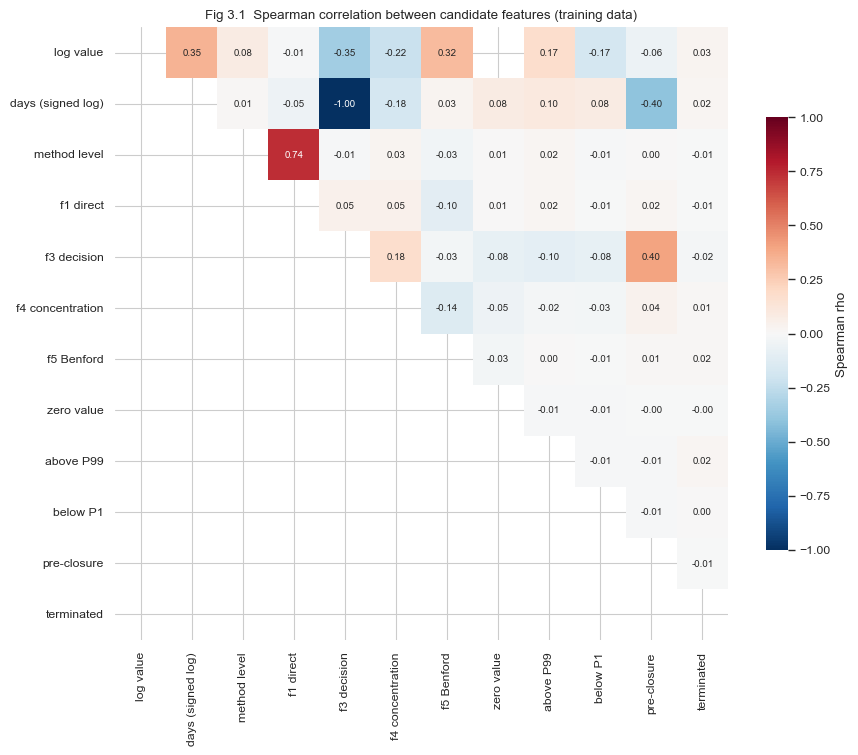

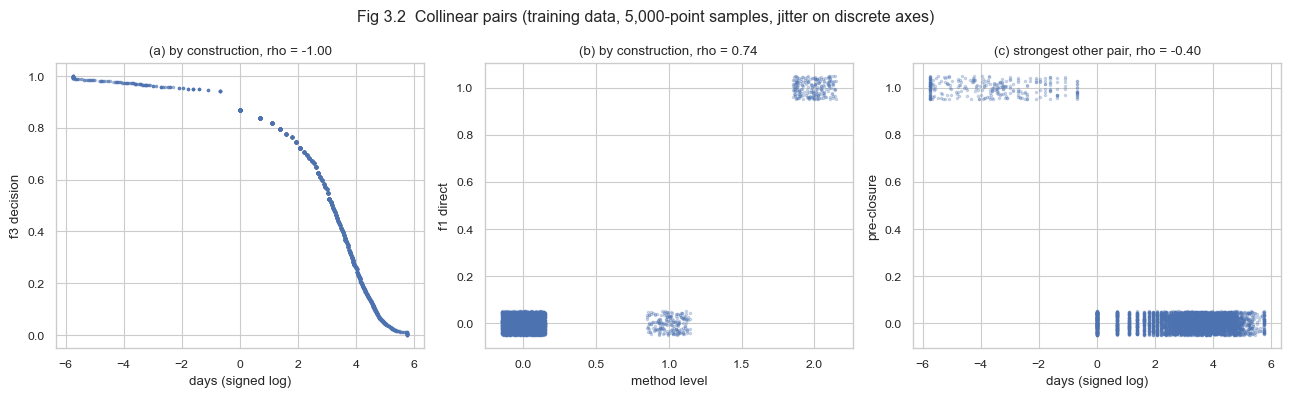

In [97]:
# step 5: correlation, VIF and mutual information (training data, step 4 transforms applied)
import importlib, src.entity_resolution, src.features
importlib.reload(src.entity_resolution); importlib.reload(src.features)
from src.features import IndicatorBuilder
from sklearn.feature_selection import mutual_info_regression

ib5 = IndicatorBuilder().fit(X_train)   # refit so below_p1 exists
F = ib5.transform(X_train)
signed_log = lambda d: np.sign(d) * np.log1p(np.abs(d))

# step 4 transforms, thresholds from training data
v = F["value_amount"].astype(float)
F["log_value"] = np.log1p(v.where(v > 0).clip(ib5.p1_, ib5.p99_))
d = F["days_to_signing"]
d1, d99 = d.quantile([0.01, 0.99])
F["days_slog"] = signed_log(d.clip(d1, d99))
print(f"frozen step 4 thresholds (train): value P1 {ib5.p1_:,.0f} | P99 {ib5.p99_:,.0f} KES | days P1 {d1:.0f} | P99 {d99:.0f}")

cand = ["log_value", "days_slog", "method_level", "f1_direct_award", "f3_decision_period",
        "f4_supplier_concentration", "f5_benford_deviation", "zero_value_award", "above_p99",
        "below_p1", "is_signed_pre_closure", "is_terminated"]
short = {"log_value": "log value", "days_slog": "days (signed log)", "method_level": "method level",
         "f1_direct_award": "f1 direct", "f3_decision_period": "f3 decision", "f4_supplier_concentration": "f4 concentration",
         "f5_benford_deviation": "f5 Benford", "zero_value_award": "zero value", "above_p99": "above P99",
         "below_p1": "below P1", "is_signed_pre_closure": "pre-closure", "is_terminated": "terminated"}
print("coverage (non-missing, train):", F[cand].notna().mean().round(3).rename(short).to_dict(), "\n")

# 1. pairwise Spearman (pairwise complete)
rho = F[cand].corr(method="spearman")
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename("rho").reset_index()
pairs["abs"] = pairs["rho"].abs()
pairs = pairs.sort_values("abs", ascending=False)
print("strongest pairs (Spearman):")
print(pairs.head(8).assign(level_0=lambda p: p["level_0"].map(short), level_1=lambda p: p["level_1"].map(short))
      [["level_0", "level_1", "rho"]].round(3).to_string(index=False))
print(f"pairs with |rho| >= 0.85: {(pairs['abs'] >= 0.85).sum()}\n")

# 2. VIF on standardised inputs (median imputation, as a model would see them)
def vif(cols):
    Z = F[cols].fillna(F[cols].median())
    Z = Z.loc[:, Z.std() > 0]
    inv = np.linalg.pinv(np.corrcoef(Z.to_numpy(), rowvar=False))
    return pd.Series(np.diag(inv), index=Z.columns).rename(short).round(2).sort_values(ascending=False)

model_in = [c for c in cand if c not in ["f1_direct_award", "f3_decision_period"]]
print("VIF, all candidates:", vif(cand).to_dict())
print("VIF, planned model inputs (f1, f3 excluded):", vif(model_in).to_dict(), "\n")

# 3. mutual information against the target (leave-one-out where circular)
target = {"f1_direct_award": "R_minus_f1_direct_award", "method_level": "R_minus_f1_direct_award",
          "is_signed_pre_closure": "R_minus_f3_decision_period",
          "f3_decision_period": "R_minus_f3_decision_period", "days_slog": "R_minus_f3_decision_period",
          "f4_supplier_concentration": "R_minus_f4_supplier_concentration",
          "f5_benford_deviation": "R_minus_f5_benford_deviation"}
binary = {"f1_direct_award", "zero_value_award", "above_p99", "below_p1", "is_signed_pre_closure", "is_terminated"}
mi = {}
for c in cand:
    tgt = target.get(c, "R")
    xy = F[[c, tgt]].dropna()
    xy = xy.sample(min(len(xy), 20000), random_state=0)
    mi[short[c]] = (mutual_info_regression(xy[[c]], xy[tgt], discrete_features=c in binary, random_state=0)[0],
                    "R" if tgt == "R" else "R minus " + tgt.split("_minus_")[1].split("_")[0])
mi = pd.DataFrame(mi, index=["MI", "target"]).T.sort_values("MI", ascending=False)
mi["MI"] = mi["MI"].astype(float).round(4)
print("mutual information (reported only, not used to choose drops):")
print(mi.to_string(), "\n")

# fig 3.1: upper-triangle heatmap
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.tril(np.ones(rho.shape, bool))
sns.heatmap(rho.rename(index=short, columns=short), mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Spearman rho", "shrink": 0.7},
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Fig 3.1  Spearman correlation between candidate features (training data)")
fig.tight_layout()
fig.savefig(FIG / "fig3_1_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# fig 3.2: the two pairs collinear by construction, plus the strongest other pair
pre = [{"days_slog", "f3_decision_period"}, {"method_level", "f1_direct_award"}]
other = pairs[[{a, b} not in pre for a, b in zip(pairs["level_0"], pairs["level_1"])]].iloc[0]
show = [("days_slog", "f3_decision_period"), ("method_level", "f1_direct_award"), (other["level_0"], other["level_1"])]
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (x, y) in zip(ax, show):
    s = F[[x, y]].dropna().sample(min(5000, F[[x, y]].dropna().shape[0]), random_state=0)
    jx = rng.uniform(-0.15, 0.15, len(s)) if F[x].nunique() <= 5 else 0
    jy = rng.uniform(-0.05, 0.05, len(s)) if F[y].nunique() <= 5 else 0
    a.scatter(s[x] + jx, s[y] + jy, s=3, alpha=0.25)
    a.set(xlabel=short[x], ylabel=short[y], title=f"rho = {rho.loc[x, y]:.2f}")
ax[0].set_title(f"(a) by construction, rho = {rho.loc[show[0]]:.2f}")
ax[1].set_title(f"(b) by construction, rho = {rho.loc[show[1]]:.2f}")
ax[2].set_title(f"(c) strongest other pair, rho = {rho.loc[show[2]]:.2f}")
fig.suptitle("Fig 3.2  Collinear pairs (training data, 5,000-point samples, jitter on discrete axes)")
fig.tight_layout()
fig.savefig(FIG / "fig3_2_collinear_scatterplots.png", dpi=300, bbox_inches="tight")
plt.show()

In [98]:
print(mi.to_string())

                       MI      target
f5 Benford         0.6794  R minus f5
f3 decision        0.5274  R minus f3
days (signed log)  0.5209  R minus f3
f4 concentration   0.1026  R minus f4
log value          0.0867           R
method level       0.0421  R minus f1
pre-closure        0.0189  R minus f3
below P1           0.0140           R
zero value         0.0123           R
f1 direct          0.0109  R minus f1
above P99          0.0032           R
terminated         0.0006           R


### Step 6: feature-to-target tests (rule written before running)

Tests follow the Phase 1 matrix (Table 5), with leave-one-out targets where a feature is part of, or a function of, R(c). Phase 2 flags (above_p99, below_p1, is_signed_pre_closure) use point-biserial r; the pre-closure flag is tested against R minus f3. Results are reported as evidence only: no feature is dropped for weak association with R(c), because R(c) is a heuristic score rather than ground truth. With n ≈ 70,000, almost every p-value will be small, so effect sizes are the basis for interpretation.

          feature     target           test  effect         p     n  positives       source
 supplier missing          R point-biserial   0.289         0 72585      24506      Table 5
       terminated          R   Mann-Whitney  -0.117    0.0612 72585         86      Table 5
       f5 Benford R minus f5       Spearman -0.0844 8.32e-107 67397       <NA>      Table 5
       zero value          R point-biserial -0.0593  1.81e-57 72585        759      Table 5
 f4 concentration R minus f4       Spearman  0.0554  2.04e-33 47252       <NA>      Table 5
        above P99          R point-biserial -0.0468  1.55e-36 72585        719 Phase 2 flag
         below P1          R point-biserial -0.0379  1.76e-24 72585        719 Phase 2 flag
days (signed log) R minus f3       Spearman -0.0299  5.73e-15 67978       <NA>      Table 5
      f3 decision R minus f3       Spearman  0.0299  5.74e-15 67978       <NA>      Table 5
        f1 direct R minus f1 point-biserial -0.0257  4.55e-12 72357       3087  

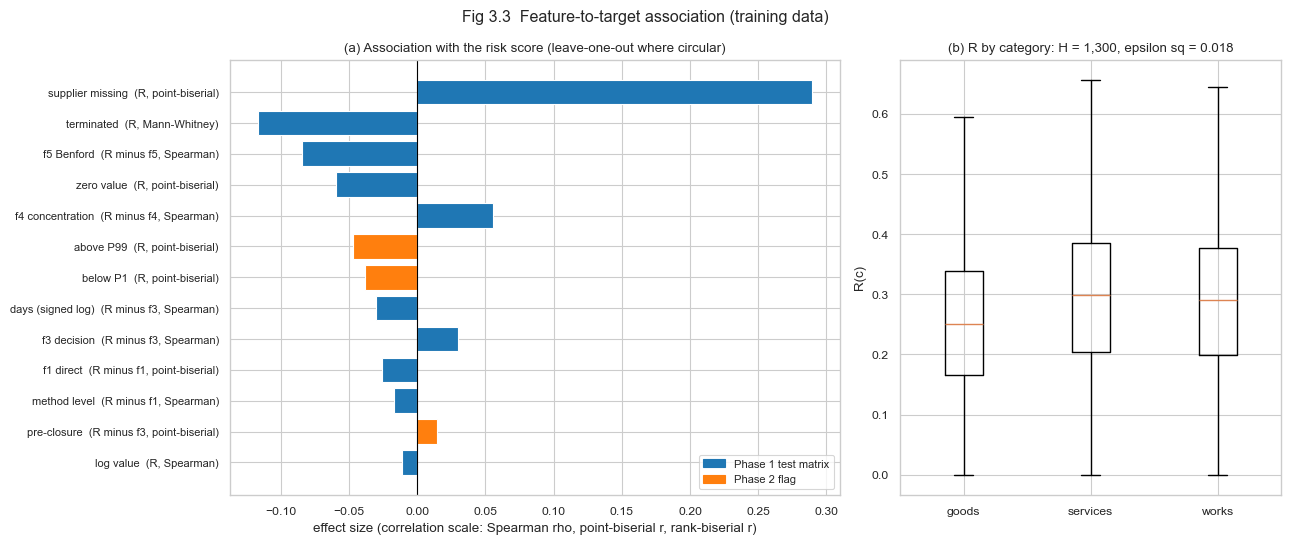

In [99]:
# step 6: feature-to-target tests (Phase 1 Table 5), leave-one-out targets where circular
from scipy.stats import spearmanr, pointbiserialr, kruskal, mannwhitneyu
short["supplier_missing"] = "supplier missing"

R1, R3, R4, R5 = ("R_minus_f1_direct_award", "R_minus_f3_decision_period",
                  "R_minus_f4_supplier_concentration", "R_minus_f5_benford_deviation")
plan = [  # feature, target, test, source
    ("f1_direct_award", R1, "point-biserial", "Table 5"),
    ("f3_decision_period", R3, "Spearman", "Table 5"),
    ("f4_supplier_concentration", R4, "Spearman", "Table 5"),
    ("f5_benford_deviation", R5, "Spearman", "Table 5"),
    ("log_value", "R", "Spearman", "Table 5"),
    ("days_slog", R3, "Spearman", "Table 5"),
    ("method_level", R1, "Spearman", "Table 5"),
    ("supplier_missing", "R", "point-biserial", "Table 5"),
    ("zero_value_award", "R", "point-biserial", "Table 5"),
    ("is_terminated", "R", "Mann-Whitney", "Table 5"),
    ("above_p99", "R", "point-biserial", "Phase 2 flag"),
    ("below_p1", "R", "point-biserial", "Phase 2 flag"),
    ("is_signed_pre_closure", R3, "point-biserial", "Phase 2 flag"),
]
rows = []
for feat, tgt, test, src in plan:
    xy = F[[feat, tgt]].dropna()
    x, y = xy[feat], xy[tgt]
    if test == "Spearman":
        eff, p = spearmanr(x, y)
    elif test == "point-biserial":
        eff, p = pointbiserialr(x, y)
    else:  # rank-biserial from Mann-Whitney U, positive if the flagged group scores higher
        u, p = mannwhitneyu(y[x == 1], y[x == 0])
        eff = 2 * u / ((x == 1).sum() * (x == 0).sum()) - 1
    rows.append(dict(feature=short.get(feat, feat), target="R" if tgt == "R" else "R minus " + tgt.split("_minus_")[1].split("_")[0],
                     test=test, effect=eff, p=p, n=len(xy), positives=int(x.sum()) if test != "Spearman" else None, source=src))
res = pd.DataFrame(rows).sort_values("effect", key=abs, ascending=False)
res["positives"] = res["positives"].astype("Int64")
with pd.option_context("display.float_format", "{:.3g}".format):
    print(res.to_string(index=False), "\n")

# category (nominal): Kruskal-Wallis with epsilon squared, plus MI
cat = F["tender_mainProcurementCategory"]
ok = cat.notna() & F["R"].notna()
groups = [F.loc[ok & (cat == c), "R"] for c in sorted(cat[ok].unique())]
H, p_kw = kruskal(*groups)
n_kw = int(ok.sum())
eps2 = H / (n_kw - 1)
mi_cat = mutual_info_regression(cat[ok].astype("category").cat.codes.to_frame(), F.loc[ok, "R"],
                                discrete_features=True, random_state=0)[0]
print(f"category vs R: Kruskal-Wallis H {H:,.1f}, p {p_kw:.3g}, epsilon squared {eps2:.4f}, MI {mi_cat:.4f}, n {n_kw:,}")
print("median R by category:", F.loc[ok].groupby(cat[ok])["R"].median().round(3).to_dict())

# fig 3.3
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
r = res.iloc[::-1]
colors = r["source"].map({"Table 5": "tab:blue", "Phase 2 flag": "tab:orange"})
ax[0].barh([f"{f}  ({t}, {s})" for f, t, s in zip(r["feature"], r["target"], r["test"])], r["effect"], color=colors)
ax[0].axvline(0, color="black", lw=0.8)
ax[0].set(xlabel="effect size (correlation scale: Spearman rho, point-biserial r, rank-biserial r)",
          title="(a) Association with the risk score (leave-one-out where circular)")
ax[0].tick_params(axis="y", labelsize=8)
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color="tab:blue"), plt.Rectangle((0, 0), 1, 1, color="tab:orange")],
             labels=["Phase 1 test matrix", "Phase 2 flag"], loc="lower right", fontsize=8)
order = sorted(cat[ok].unique())
ax[1].boxplot([F.loc[ok & (cat == c), "R"] for c in order], showfliers=False)
ax[1].set_xticks(range(1, len(order) + 1), order)
ax[1].set(ylabel="R(c)", title=f"(b) R by category: H = {H:,.0f}, epsilon sq = {eps2:.3f}")
fig.suptitle("Fig 3.3  Feature-to-target association (training data)")
fig.tight_layout()
fig.savefig(FIG / "fig3_3_target_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [100]:
# does R depend on how many indicators are available?
from src.features import INDICATORS
n_avail = F[INDICATORS].notna().sum(axis=1)
print(F.groupby(n_avail)["R"].agg(["size", "mean", "median"]).round(3).to_string(), "\n")
print("mean of each indicator where available:", F[INDICATORS].mean().round(3).to_dict())

    size   mean  median
1    228  0.022   0.000
2   4592  0.256   0.242
3  25260  0.312   0.314
4  42505  0.262   0.265 

mean of each indicator where available: {'f1_direct_award': 0.043, 'f3_decision_period': 0.493, 'f4_supplier_concentration': 0.005, 'f5_benford_deviation': 0.5}


pipeline fitted on X_train in 4s

train: raw 72,585 x 23 -> indicators 72,585 x 43 -> model input 72,585 x 14 | rows kept True | NaN 0
test: raw 36,399 x 23 -> indicators 36,399 x 43 -> model input 36,399 x 14 | rows kept True | NaN 0

model inputs: ['value_amount', 'days_to_signing', 'method_level', 'tender_mainProcurementCategory_services', 'tender_mainProcurementCategory_works', 'f4_supplier_concentration', 'f5_benford_deviation', 'missingindicator_f4_supplier_concentration', 'missingindicator_f5_benford_deviation', 'zero_value_award', 'above_p99', 'below_p1', 'is_signed_pre_closure', 'is_terminated'] 

train: anomaly score median 0.407 | P95 0.561 | Spearman with R(c) 0.141
test: anomaly score median 0.393 | P95 0.544 | Spearman with R(c) 0.212

skewness and kurtosis by stage (train):
  value            raw                              skew   137.48 | kurtosis   20892.26 | n 72,585
  value            clipped P1/P99, zeros imputed    skew     6.19 | kurtosis      41.32 | n 72,585
  

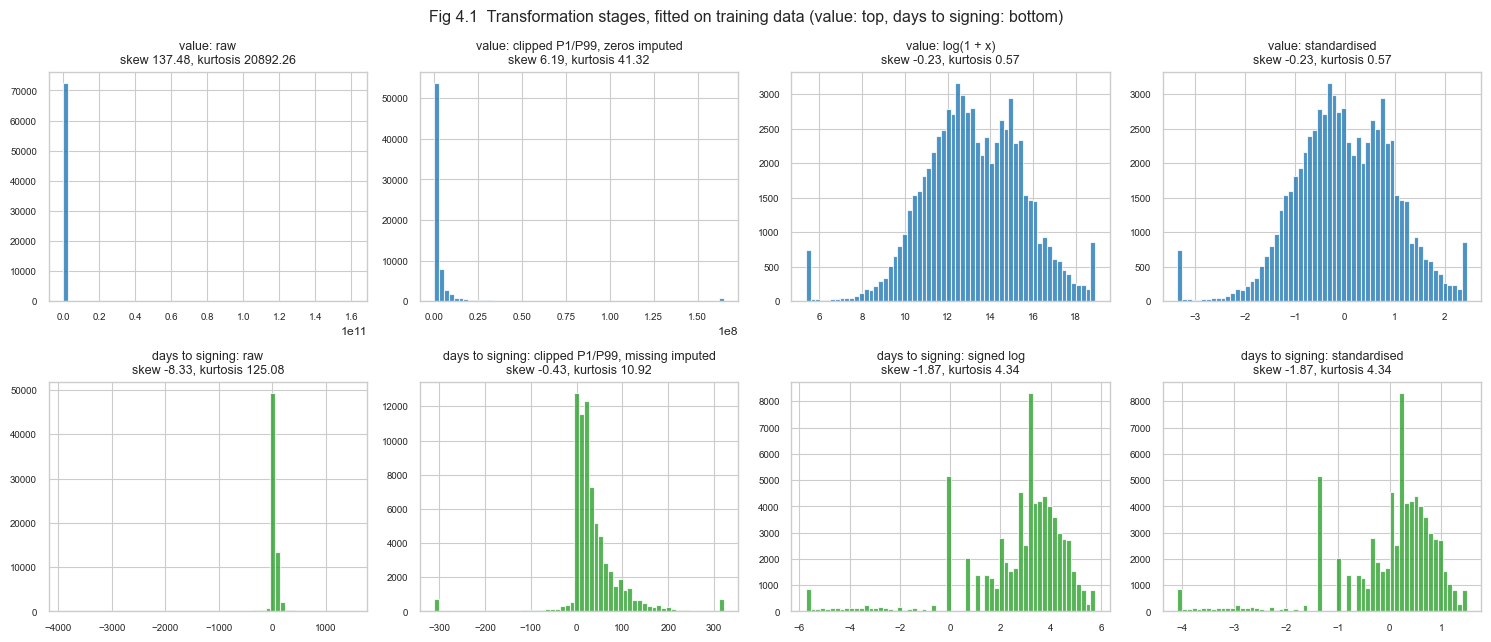

In [101]:
# step 7: full pipeline fit on X_train only, N x P check, Fig 4.1
import time, importlib, src.entity_resolution, src.features, src.transformers, src.pipeline
for m in (src.entity_resolution, src.features, src.transformers, src.pipeline):
    importlib.reload(m)
from scipy.stats import skew, kurtosis, spearmanr
from src.pipeline import build_pipeline, CATEGORY, METHOD
from src.transformers import signed_log

t0 = time.time()
pipe = build_pipeline(n_estimators=200, random_state=0).fit(X_train)
ib, prep = pipe.named_steps["indicators"], pipe.named_steps["prep"]
print(f"pipeline fitted on X_train in {time.time() - t0:.0f}s\n")

# N x P before and after
names = prep.get_feature_names_out()
for label, X in [("train", X_train), ("test", X_test)]:
    Fx = ib.transform(X)
    Z = prep.transform(Fx)
    print(f"{label}: raw {X.shape[0]:,} x {X.shape[1]} -> indicators {Fx.shape[0]:,} x {Fx.shape[1]} -> model input {Z.shape[0]:,} x {Z.shape[1]}"
          f" | rows kept {Z.shape[0] == X.shape[0]} | NaN {int(np.isnan(Z).sum())}")
print("\nmodel inputs:", [n.split("__", 1)[1] for n in names], "\n")

# Isolation Forest scores (higher = more anomalous)
for label, X in [("train", X_train), ("test", X_test)]:
    s = -pipe.score_samples(X)
    r = ib.transform(X)["R"]
    print(f"{label}: anomaly score median {np.median(s):.3f} | P95 {np.quantile(s, 0.95):.3f} | "
          f"Spearman with R(c) {spearmanr(s, r, nan_policy='omit')[0]:.3f}")

# Fig 4.1: each stage of the two continuous features, on training data
Ftr = ib.transform(X_train)
vp, dp = prep.named_transformers_["value"], prep.named_transformers_["days"]
v1 = vp[0].transform(Ftr[["value_amount", CATEGORY]]).ravel()
d1 = dp[0].transform(Ftr[["days_to_signing", METHOD]]).ravel()
stages = {
    "value": [("raw", Ftr["value_amount"].to_numpy(dtype=float)), ("clipped P1/P99, zeros imputed", v1),
              ("log(1 + x)", np.log1p(v1)), ("standardised", vp[2].transform(np.log1p(v1).reshape(-1, 1)).ravel())],
    "days to signing": [("raw", Ftr["days_to_signing"].to_numpy(dtype=float)), ("clipped P1/P99, missing imputed", d1),
                        ("signed log", signed_log(d1)), ("standardised", dp[2].transform(signed_log(d1).reshape(-1, 1)).ravel())],
}
print("\nskewness and kurtosis by stage (train):")
fig, ax = plt.subplots(2, 4, figsize=(15, 6.5))
for i, (feat, steps) in enumerate(stages.items()):
    for j, (stage, x) in enumerate(steps):
        x = x[np.isfinite(x)]
        sk, ku = skew(x), kurtosis(x)
        print(f"  {feat:16s} {stage:32s} skew {sk:8.2f} | kurtosis {ku:10.2f} | n {len(x):,}")
        ax[i, j].hist(x, bins=60, color="tab:blue" if i == 0 else "tab:green", alpha=0.8)
        ax[i, j].set_title(f"{feat}: {stage}\nskew {sk:.2f}, kurtosis {ku:.2f}", fontsize=9)
        ax[i, j].tick_params(labelsize=7)
fig.suptitle("Fig 4.1  Transformation stages, fitted on training data (value: top, days to signing: bottom)")
fig.tight_layout()
fig.savefig(FIG / "fig4_1_transformation_grid.png", dpi=300, bbox_inches="tight")
plt.show()

input: 72,585 x 14 standardised features (train)
      eigenvalue  variance %  cumulative %
PC1         2.09       14.91         14.91
PC2         1.54       10.98         25.89
PC3         1.30        9.28         35.17
PC4         1.11        7.90         43.07
PC5         1.07        7.62         50.69
PC6         1.02        7.28         57.97
PC7         1.01        7.20         65.17
PC8         0.99        7.10         72.26
PC9         0.95        6.82         79.08
PC10        0.92        6.54         85.63
PC11        0.83        5.93         91.56
PC12        0.52        3.74         95.30
PC13        0.44        3.16         98.46
PC14        0.22        1.54        100.00

components for 90%: 11 | for 95%: 12 | eigenvalue > 1 (Kaiser): 7 of 14

PC1 top loadings: {'days_to_signing': 0.51, 'tender_mainProcurementCategory_works': 0.44, 'is_signed_pre_closure': -0.42, 'value_amount': 0.39}
PC2 top loadings: {'is_signed_pre_closure': 0.54, 'days_to_signing': -0.45, 'value_amoun

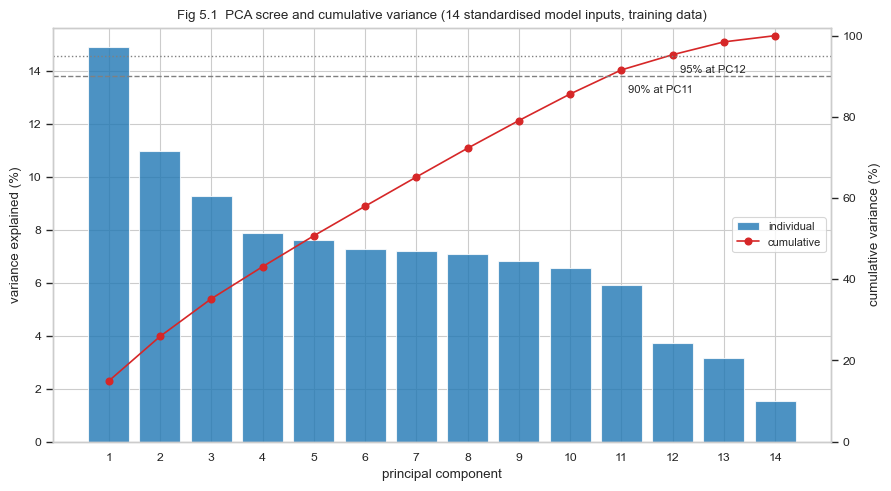

In [102]:
# step 8a: PCA on the model input matrix (diagnostic only, fitted on train)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

feat = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
Ztr = prep.transform(ib.transform(X_train))
Zs = StandardScaler().fit_transform(Ztr)   # one-hot columns are not scaled in the pipeline
pca = PCA().fit(Zs)
ev, ratio = pca.explained_variance_, pca.explained_variance_ratio_
cum = np.cumsum(ratio)
k90, k95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)
print(f"input: {Zs.shape[0]:,} x {Zs.shape[1]} standardised features (train)")
print(pd.DataFrame({"eigenvalue": ev, "variance %": ratio * 100, "cumulative %": cum * 100},
                   index=[f"PC{i + 1}" for i in range(len(ev))]).round(2).to_string())
print(f"\ncomponents for 90%: {k90} | for 95%: {k95} | eigenvalue > 1 (Kaiser): {(ev > 1).sum()} of {len(ev)}\n")
load = pd.DataFrame(pca.components_[:3].T, index=feat, columns=["PC1", "PC2", "PC3"])
for pc in load:
    top = load[pc].abs().sort_values(ascending=False).head(4).index
    print(f"{pc} top loadings:", {f: round(float(load.loc[f, pc]), 2) for f in top})

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(1, len(ev) + 1)
ax.bar(x, ratio * 100, color="tab:blue", alpha=0.8, label="individual")
ax2 = ax.twinx()
ax2.plot(x, cum * 100, color="tab:red", marker="o", label="cumulative")
for lvl, k, ls in [(90, k90, "--"), (95, k95, ":")]:
    ax2.axhline(lvl, color="grey", ls=ls, lw=1)
    ax2.annotate(f"{lvl}% at PC{k}", (k, lvl), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax.set(xlabel="principal component", ylabel="variance explained (%)", xticks=x)
ax2.set(ylabel="cumulative variance (%)", ylim=(0, 102))
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8)
ax.set_title("Fig 5.1  PCA scree and cumulative variance (14 standardised model inputs, training data)")
fig.tight_layout()
fig.savefig(FIG / "fig5_1_pca_scree_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [103]:
# step 8b: tuning by rank stability, with anomaly injection (training period only)
import time, importlib, src.tuning
importlib.reload(src.tuning)
from src.tuning import run_grid, summarise

t0 = time.time()
grid = run_grid(X_train, trees=(100, 200, 400), samples=(256, 1024, 4096), seeds=(0, 1),
                n_splits=5, frac=0.02, top=0.95)
print(f"\ngrid finished in {(time.time() - t0) / 60:.1f} min\n")

table, pick = summarise(grid, tie=0.005)
print("all settings, sorted by mean rank stability (5 time-ordered folds, 2 seeds):")
print(table.round(4).to_string(index=False), "\n")
print("rank stability by fold:")
print(grid.pivot_table(index=["trees", "max_samples"], columns="fold", values="stability").round(4).to_string(), "\n")
print("injection recall by fold (value | date):")
print(grid.pivot_table(index=["trees", "max_samples"], columns="fold", values=["recall_value", "recall_date"]).round(3).to_string(), "\n")
print(f"pre-specified rule selects: {int(pick['trees'])} trees, max_samples {int(pick['max_samples'])} "
      f"(stability {pick['stability']:.4f}, recall value {pick['recall_value']:.3f}, date {pick['recall_date']:.3f})")

out = ROOT / "results"
out.mkdir(exist_ok=True)
grid.to_csv(out / "if_tuning_by_fold.csv", index=False)
table.to_csv(out / "if_tuning_summary.csv", index=False)
print("saved to", out)

fold 1: train 12,100 | validation 12,097 | injected 241 value + 241 date
fold 2: train 24,197 | validation 12,097 | injected 241 value + 241 date
fold 3: train 36,294 | validation 12,097 | injected 241 value + 241 date
fold 4: train 48,391 | validation 12,097 | injected 241 value + 241 date
fold 5: train 60,488 | validation 12,097 | injected 241 value + 241 date

grid finished in 0.6 min

all settings, sorted by mean rank stability (5 time-ordered folds, 2 seeds):
 trees  max_samples  stability  stability_sd  recall_value  recall_date  recall_mean
   400         1024     0.9928        0.0015        0.1834       0.7324       0.4579
   400         4096     0.9922        0.0052        0.1946       0.6025       0.3985
   400          256     0.9916        0.0015        0.1166       0.8423       0.4795
   200         1024     0.9879        0.0035        0.1809       0.7174       0.4492
   200         4096     0.9865        0.0068        0.1954       0.5963       0.3959
   200          256  

In [104]:
# step 8c: final model, refit on the full training period with the selected setting
import importlib, src.pipeline
importlib.reload(src.pipeline)
from src.pipeline import build_pipeline
from scipy.stats import spearmanr

final = build_pipeline(n_estimators=400, max_samples=256, random_state=0).fit(X_train)
ibf = final.named_steps["indicators"]
s_tr, s_te = -final.score_samples(X_train), -final.score_samples(X_test)
thr = np.quantile(s_tr, 0.95)   # top-5% cut-off fixed on training scores
for label, X, s in [("train", X_train, s_tr), ("test", X_test, s_te)]:
    r = ibf.transform(X)["R"]
    print(f"{label}: median score {np.median(s):.3f} | above train top-5% cut-off {(s > thr).mean():.1%} | "
          f"Spearman with R(c) {spearmanr(s, r, nan_policy='omit')[0]:.3f}")

key = "main_ocid" if "main_ocid" in X_test.columns else "ocid"
Fte = ibf.transform(X_test)
cols = [key, "buyer_name", "tender_procurementMethod", "value_amount", "days_to_signing", "f4_supplier_concentration",
        "f5_benford_deviation", "above_p99", "below_p1", "is_signed_pre_closure", "R"]
scores = Fte[[c for c in cols if c in Fte.columns]].assign(anomaly_score=s_te, top5=s_te > thr)
scores.sort_values("anomaly_score", ascending=False).to_csv(ROOT / "results" / "test_scores.csv", index=False)
print(f"\nsaved {len(scores):,} test scores to results/test_scores.csv ({int(scores['top5'].sum()):,} above the cut-off)")

train: median score 0.409 | above train top-5% cut-off 5.0% | Spearman with R(c) 0.145
test: median score 0.397 | above train top-5% cut-off 3.1% | Spearman with R(c) 0.219

saved 36,399 test scores to results/test_scores.csv (1,131 above the cut-off)
